In [1]:
from dotenv import load_dotenv

load_dotenv()

True

### Supervisor 형 멀티에이전트 개발

#### LLM 선언

In [2]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model='llama3.1:latest', 
    num_predict=512,
)

In [3]:
# 에이전트 생성

# 1. Market Research 시장조사 에이전트
# 2. Stock Research 주식조사 에이전트
# 3. 재무제표 분석 에이전트 - 야후 API 활용

# 자료조사가 끝나면, 최종적으로 투자를 할지 말지 결정한다. 

```text

                         사용자 투자 조사 요청
                                  │
                                  │
          ┌───────────────────────┼───────────────────────┐
          ▼                       ▼                       ▼
   Market Research         Stock Research          Financial Analysis
   시장조사 에이전트       주식조사 에이전트       재무제표 분석 에이전트
          │                       │                       │
          │                       │                       │
          └───────────────────────┼───────────────────────┘
                                  ▼
                      관리자 에이전트 (Supervisor)
                      ┌─────────────────────────┐
                      │ 조사 결과 종합          │
                      │ 상충하는 의견 검토      │
                      │ 수익 기회·위험 평가     │
                      │ 최종 투자 여부 판단     │
                      └─────────────────────────┘
                                  │
                                  ▼
                       판단 근거와 최종 보고서

```

#### 1. Market Research Agent

In [4]:
# yfinance 툴 활용

In [5]:
from langchain_community.tools.yahoo_finance_news import YahooFinanceNewsTool
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage
from langgraph.graph import MessagesState
from langgraph.types import Command
from typing import Literal



# 레거시에서는 state_modifier(프롬프트의 간소화된 버전? 페르소나 부여 역할) 로 지정을 했으나, TypeError
# system_prompt 로 줘야 함
market_research_agent = create_agent(
    model=llm,
    tools=[YahooFinanceNewsTool()],
    system_prompt = 'You are a market researcher. Provide fact only not opinions'
)


# 에이전트 호출 노드 
def market_research_node(state: MessagesState) -> Command[Literal["supervisor"]]:
    result = market_research_agent.invoke(state)
    print(f'market_research_node == {result}')

    # 에이전트 실행 후, supervisor로 향하도록
    return Command(
        update={
            'messages': [HumanMessage(content=result['messages'][-1].content, name='market_research')]   # create_agent 는 생각을 하는 에이전트이기 때문에, 결과가 매우 길다. 일단 마지막 메시지만 넘겨준다. (최종 결론만 state에 남기는 것)
        },
        goto='supervisor'
    )

C:\Users\Yurim Park\AppData\Local\Temp\ipykernel_42204\2588296899.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.yahoo_finance_news import YahooFinanceNewsTool
USER_AGENT environment variable not set, consider setting it to identify your requests.


#### Stock Research Agent
- stock 데이터 로드 - 커스텀 툴로 생성


In [6]:
# yfinance 에서 로드
import yfinance as yf
from langchain.tools import tool

@tool
def get_stock_price(ticker:str) -> dict:
    """Given a stock ticker, return the price data for the past month"""

    stock_info = yf.download(ticker, period='1mo').to_dict()
    print(f'stock_info === {stock_info}')
    return stock_info

stock_research_tools = [get_stock_price]
stock_research_tools

[StructuredTool(name='get_stock_price', description='Given a stock ticker, return the price data for the past month', args_schema=<class 'langchain_core.utils.pydantic.get_stock_price'>, func=<function get_stock_price at 0x0000026D7C5036A0>)]

In [7]:
stock_research_agent = create_agent(
    model=llm,
    tools=stock_research_tools,
    system_prompt = 'You are a stock researcher. Provide fact only not opinions'
)


def stock_research_node(state:MessagesState) -> Command[Literal["supervisor"]]:
    result = stock_research_agent.invoke(state)

    return Command(
        update={
            'messages': [HumanMessage(content=result['messages'][-1].content, name='stock_research')]   # create_agent 는 생각을 하는 에이전트이기 때문에, 결과가 매우 길다. 일단 마지막 메시지만 넘겨준다. (최종 결론만 state에 남기는 것)
        },
        goto='supervisor'
    )

#### 재무제표 노드

In [8]:
@tool
def company_research_tool(ticker: str) -> dict:
    """Given a ticker, return the financial information and SEC filings"""
    company_info = yf.Ticker(ticker)
    financial_info = company_info.get_financials()
    sec_filings = company_info.get_sec_filings()

    return {
        'financial_info': financial_info,
        'sec_filings' : sec_filings
    }


company_research_tools = [company_research_tool]
company_research_tools

[StructuredTool(name='company_research_tool', description='Given a ticker, return the financial information and SEC filings', args_schema=<class 'langchain_core.utils.pydantic.company_research_tool'>, func=<function company_research_tool at 0x0000026D4B3787C0>)]

In [9]:
company_research_agent = create_agent(
    model=llm,
    tools=company_research_tools,
    system_prompt = 'You are a company researcher. Provide fact only not opinions'
)


def company_research_node(state:MessagesState) -> Command[Literal["supervisor"]]:
    result = company_research_agent.invoke(state)

    return Command(
        update={
            'messages': [HumanMessage(content=result['messages'][-1].content, name='company_research')] 
        },
        goto='supervisor'
    )

#### Supervisor 생성

- langgraph 에서 활용하는게 제일 좋음

In [10]:
from typing import Literal
from typing_extensions import TypedDict

from langgraph.graph import MessagesState, END
from langgraph.types import Command


members = ["market_research", "stock_research", "company_research"]
options = members + ["FINISH"]

system_prompt = (
    "You are a supervisor tasked with managing a conversation between the"
    f" following workers: {members}. Given the following user request,"
    " respond with the worker to act next. Each worker will perform a"
    " task and respond with their results and status. When finished,"
    " respond with FINISH."
)


class Router(TypedDict):
    """Worker to route to next. If no workers needed, route to FINISH."""

    next: Literal[
        "market_research",
        "stock_research",
        "company_research",
        "FINISH"]



def supervisor_node(state: MessagesState) -> Command[Literal[
        "market_research",
        "stock_research",
        "company_research", 
        ]]:

    messages = [
        {"role": "system", "content": system_prompt},
    ] + state["messages"]

    response = llm.with_structured_output(Router).invoke(messages)
    goto = response["next"]
    if goto == "FINISH":
        goto = END

    return Command(goto=goto)

#### 그래프 빌드

In [11]:
from langgraph.graph import StateGraph, START

graph_builder = StateGraph(MessagesState)

## 노드 추가
graph_builder.add_node("supervisor", supervisor_node)
graph_builder.add_node("market_research", market_research_node)
graph_builder.add_node("stock_research", stock_research_node)
graph_builder.add_node("company_research", company_research_node)



In [12]:
# 엣지 추가

graph_builder.add_edge(START, "supervisor")

# 위 노드들에서 conditional 로 처리가 되었기 때문에 엣지 추가는 필요 없음

In [13]:
graph = graph_builder.compile()

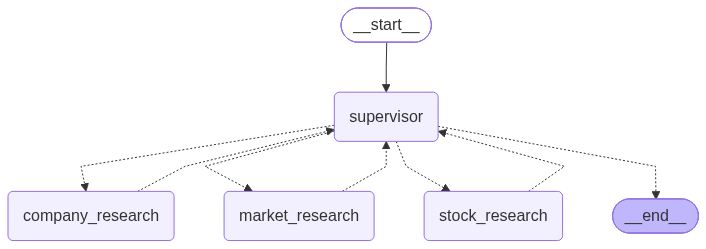

In [14]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
# 테스트
for chunk in graph.stream(
    {"messages": [("user", "Would you invest in Snowflake?")]}, stream_mode="values"
):
    chunk['messages'][-1].pretty_print()

================================ Human Message =================================

Would you invest in Snowflake?
market_research_node == {'messages': [HumanMessage(content='Would you invest in Snowflake?', additional_kwargs={}, response_metadata={}, id='8f96e9ef-3d40-4a35-8b6f-439b39cb7325'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.1:latest', 'created_at': '2026-10-18T08:36:24.0761726Z', 'done': True, 'done_reason': 'stop', 'total_duration': 6650094700, 'load_duration': 16514000, 'prompt_eval_count': 209, 'prompt_eval_duration': 4234488999, 'eval_count': 20, 'eval_duration': 2388225000, 'logprobs': None, 'model_name': 'llama3.1:latest', 'model_provider': 'ollama'}, id='lc_run--01a14e27-8d91-71d2-8e52-b96b23a73160-0', tool_calls=[{'name': 'yahoo_finance_news', 'args': {'query': 'SNOW'}, 'id': '2938c9e2-f301-42d8-b98e-a7e649b1f364', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 209, 'output_tokens': 20, 'total_tokens

[*********************100%***********************]  1 of 1 completed


stock_info === {('Close', 'SNOW'): {Timestamp('2026-09-17 00:00:00'): 338.3900146484375, Timestamp('2026-09-18 00:00:00'): 332.42999267578125, Timestamp('2026-09-21 00:00:00'): 339.3900146484375, Timestamp('2026-09-22 00:00:00'): 336.5899963378906, Timestamp('2026-09-23 00:00:00'): 334.80999755859375, Timestamp('2026-09-24 00:00:00'): 334.0, Timestamp('2026-09-25 00:00:00'): 335.94000244140625, Timestamp('2026-09-28 00:00:00'): 328.1199951171875, Timestamp('2026-09-29 00:00:00'): 330.30999755859375, Timestamp('2026-09-30 00:00:00'): 339.55999755859375, Timestamp('2026-10-01 00:00:00'): 341.989990234375, Timestamp('2026-10-02 00:00:00'): 341.0400085449219, Timestamp('2026-10-05 00:00:00'): 338.989990234375, Timestamp('2026-10-06 00:00:00'): 335.95001220703125, Timestamp('2026-10-07 00:00:00'): 332.8500061035156, Timestamp('2026-10-08 00:00:00'): 343.3999938964844, Timestamp('2026-10-09 00:00:00'): 368.8900146484375, Timestamp('2026-10-12 00:00:00'): 360.3699951171875, Timestamp('2026-10

[*********************100%***********************]  1 of 1 completed


stock_info === {('Close', 'SNOW'): {Timestamp('2026-09-17 00:00:00'): 338.3900146484375, Timestamp('2026-09-18 00:00:00'): 332.42999267578125, Timestamp('2026-09-21 00:00:00'): 339.3900146484375, Timestamp('2026-09-22 00:00:00'): 336.5899963378906, Timestamp('2026-09-23 00:00:00'): 334.80999755859375, Timestamp('2026-09-24 00:00:00'): 334.0, Timestamp('2026-09-25 00:00:00'): 335.94000244140625, Timestamp('2026-09-28 00:00:00'): 328.1199951171875, Timestamp('2026-09-29 00:00:00'): 330.30999755859375, Timestamp('2026-09-30 00:00:00'): 339.55999755859375, Timestamp('2026-10-01 00:00:00'): 341.989990234375, Timestamp('2026-10-02 00:00:00'): 341.0400085449219, Timestamp('2026-10-05 00:00:00'): 338.989990234375, Timestamp('2026-10-06 00:00:00'): 335.95001220703125, Timestamp('2026-10-07 00:00:00'): 332.8500061035156, Timestamp('2026-10-08 00:00:00'): 343.3999938964844, Timestamp('2026-10-09 00:00:00'): 368.8900146484375, Timestamp('2026-10-12 00:00:00'): 360.3699951171875, Timestamp('2026-10